# CS109a Milestone 2 — OSPAR Beach Litter

**Canvas project group number:** 35
**Group members:** Cassidy Cheng, Phoebe Pan, Eli Su

**Project question.** For beaches in the OSPAR monitoring network, can we predict the total
litter count of a beach's *next* survey using only information available *before* that survey
takes place, and do so more accurately than the beach's own historical median?

Everything below is reproducible from the raw files listed in `data/raw/SOURCE.md`.
The cleaning rules themselves live in `src/data.py`; this notebook shows the **evidence**
for each rule rather than restating the code.

---
## 1. Getting the data

OSPAR publishes the same beach-litter database through two front ends, and we need both
because neither covers the full period on its own.

| Source | What we took | Coverage |
|---|---|---|
| [beachlitter.ospar.org](https://beachlitter.ospar.org/) survey portal | 3 CSV exports, 100 m protocol, in 5-year chunks | 2001-01-01 → 2014-12-29 |
| [odims.ospar.org](https://odims.ospar.org/) | 9 annual `.xlsx` files, 100 m sampling units | 2014-12-07 → 2023-10-31 |

We started on the portal, which went down site-wide on 1 Nov (HTTP 521) and, once back,
still timed out on any range longer than about five years. ODIMS publishes static annual
files with no form in front of them, so we pulled 2015–2023 there and used three 5-year
portal exports for the earlier period. Download dates, URLs and the exact export settings
are recorded in `data/raw/SOURCE.md`.

In [1]:
import glob, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)

raw_files = sorted(glob.glob("data/raw/*.xlsx")) + sorted(glob.glob("data/*.csv"))
if raw_files:
    size_mb = sum(os.path.getsize(f) for f in raw_files) / 1e6
    print(f"{len(raw_files)} raw files, {size_mb:.1f} MB total\n")
    for f in raw_files:
        print(f"  {os.path.getsize(f)/1e6:5.2f} MB  {f}")
else:
    # A fresh clone has the cleaned panel but not the raw downloads, which are
    # gitignored. data/raw/SOURCE.md says how to obtain them.
    panel = "data/processed/panel.csv.gz"
    print("Raw files not present -- working from the committed panel.")
    print(f"  {os.path.getsize(panel)/1e6:.2f} MB  {panel}  (raw sources total 4.5 MB)")

12 raw files, 4.5 MB total

   0.20 MB  data/raw/ospar_100m_2015.xlsx
   0.28 MB  data/raw/ospar_100m_2016.xlsx
   0.29 MB  data/raw/ospar_100m_2017.xlsx
   0.31 MB  data/raw/ospar_100m_2018.xlsx
   0.34 MB  data/raw/ospar_100m_2019.xlsx
   0.30 MB  data/raw/ospar_100m_2020.xlsx
   0.25 MB  data/raw/ospar_100m_2021.xlsx
   0.38 MB  data/raw/ospar_100m_2022.xlsx
   0.36 MB  data/raw/ospar_100m_2023.xlsx
   0.50 MB  data/ospar_100m_2001_2005.csv
   0.51 MB  data/ospar_100m_2006_2010.csv
   0.82 MB  data/ospar_100m_2011_2014.csv


---
## 2. Understanding the data

### What one row is

**One row is one standardized 100 m beach-litter survey**: one beach, on one date, walked
under the OSPAR 100 m protocol, with every litter item found classified into one of ~120
type codes. This matters because OSPAR exports are often one row per *litter type per
survey*; ours are not, so no pivot is needed. `Survey ID` is unique and is what we
deduplicate on.

We deliberately excluded the **1 km protocol**, which is a different survey method with
counts that are not comparable to the 100 m ones.

### A note on OSPAR "years"

An OSPAR year runs **December to October**, split into four seasonal periods, so
"2011" means Dec 2010 → Oct 2011. `Period` is a ready-made seasonality feature, but the
Dec–Oct boundary is a trap for any year-based train/test split.

In [2]:
from src.data import load_panel, add_lags, count_columns, SUBCODE_COLUMNS

df = load_panel()
counts = count_columns(df)

print("shape:", df.shape)
print("surveys:        ", len(df))
print("beaches:        ", df["Beach ID"].nunique())
print("countries:      ", df["Country"].nunique())
print("regions:        ", df["Region"].nunique())
print("date range:     ", df["date"].min().date(), "->", df["date"].max().date())
print("count columns:  ", len(counts))
print("source split:   ", dict(df["source"].value_counts()))

shape: (5879, 171)
surveys:         5879
beaches:         247
countries:       13
regions:         7
date range:      2001-01-01 -> 2023-10-31
count columns:   116
source split:    {'odims': np.int64(3843), 'portal': np.int64(2036)}


In [3]:
df[["Beach ID", "Beach name", "Country", "Region", "Survey date", "Period", "total"]].head(8)

,Beach ID,Beach name,Country,Region,Survey date,Period,total
0,BE001,Oostende,Belgium,3. Southern North Sea,01/04/2002,2,102.0
1,BE001,Oostende,Belgium,3. Southern North Sea,01/07/2002,3,65.0
2,BE001,Oostende,Belgium,3. Southern North Sea,01/10/2002,4,56.0
3,BE001,Oostende,Belgium,3. Southern North Sea,01/01/2003,1,133.0
4,BE001,Oostende,Belgium,3. Southern North Sea,01/04/2003,2,144.0
5,BE001,Oostende,Belgium,3. Southern North Sea,01/07/2003,3,93.0
6,BE001,Oostende,Belgium,3. Southern North Sea,01/10/2003,4,121.0
7,BE001,Oostende,Belgium,3. Southern North Sea,01/01/2004,1,299.0


In [4]:
# Surveys per beach -- this is what decides the minimum history a model can ask for.
per_beach = df.groupby("Beach ID").size()
print(per_beach.describe().round(1).to_string())
print()
for k in (4, 8, 12, 20, 40):
    print(f"  beaches with >= {k:2d} surveys: {(per_beach >= k).sum():3d}")

count    247.0
mean      23.8
std       20.4
min        1.0
25%        9.0
50%       17.0
75%       36.5
max       91.0

  beaches with >=  4 surveys: 225
  beaches with >=  8 surveys: 197
  beaches with >= 12 surveys: 157
  beaches with >= 20 surveys: 107
  beaches with >= 40 surveys:  48


In [5]:
# The target. Heavily right-skewed, which is why we model log1p(total).
print(df["total"].describe().round(1).to_string())
print("\nskew:", round(df["total"].skew(), 2), " -> log1p skew:", round(df["log_total"].skew(), 2))

count      5879.0
mean        790.6
std        5582.7
min           0.0
25%          85.0
50%         227.0
75%         626.0
max      223436.7

skew: 30.14  -> log1p skew: -0.1


---
## 3. Cleaning and preprocessing

All six cleaning decisions are implemented in
`src/data.py`, so the panel any of us loads is the same panel.

### 3.1 Personal data had to be removed

The portal CSVs carry `Email` and `Survey entered by` — surveyor names and addresses.
These are dropped on load.

**Dropping the columns was not enough.** A grep for `@` found an email address sitting
inside the free-text `Divert specify` field, so `load_panel` also regex-redacts emails
from every text column. 

In [6]:
# Nothing that looks like an email address survives in the loaded panel.
text_cols = [c for c in df.columns if df[c].dtype == object]
hits = sum(df[c].astype(str).str.contains(r"[\w.\-+]+@[\w.\-]+\.\w+", regex=True).sum()
           for c in text_cols)
print("raw email-shaped strings remaining in the panel:", hits)
print("PII columns present:", [c for c in ("Email", "Survey entered by") if c in df.columns])

raw email-shaped strings remaining in the panel: 0
PII columns present: []


### 3.2 Checking the overlap: the two sources are the same database

December 2014 appears in both, which means the two data collection methods still returned the same data.

In [7]:
# Read each source separately, before the merge, so the overlap is visible.
from src.data import _read_portal, _read_odims

portal, odims = _read_portal("data"), _read_odims("data")
for frame in (portal, odims):
    frame["d"] = pd.to_datetime(frame["Survey date"], dayfirst=True, errors="coerce")

dec14 = lambda f: f[(f["d"] >= "2014-12-01") & (f["d"] <= "2014-12-31")]
p_ids, o_ids = set(dec14(portal)["Survey ID"]), set(dec14(odims)["Survey ID"])

print(f"December 2014 surveys in the portal export: {len(p_ids)}")
print(f"December 2014 surveys in the ODIMS files:   {len(o_ids)}")
print(f"Survey IDs present in BOTH:                 {len(p_ids & o_ids)}")
print(f"  only in the portal: {len(p_ids - o_ids)}    only in ODIMS: {len(o_ids - p_ids)}")
print("\nA perfect match on the identifier. The two front ends serve one database,")
print("so the overlap is a duplication trap rather than extra data.")

December 2014 surveys in the portal export: 14
December 2014 surveys in the ODIMS files:   14
Survey IDs present in BOTH:                 14
  only in the portal: 0    only in ODIMS: 0

A perfect match on the identifier. The two front ends serve one database,
so the overlap is a duplication trap rather than extra data.


**One identifier is not enough.** `Survey ID` is unique, so deduplicating on it leaves
`UK057` on 2023-09-23 in the panel twice, under IDs 22453 and 22454 — and those two rows
are **identical in every one of the 116 count columns**. That is one survey entered twice,
not two surveys.

So the loader applies a second rule: it drops exact repeats of beach + date + all counts. It
removes this one record and would leave a real same-day pair untouched. Exactly one group in the panel matches.

In [8]:
# Before the duplicate rule: two Survey IDs on the same beach and date.
raw = pd.concat([portal, odims], ignore_index=True).drop_duplicates(subset=["Survey ID"])
pair = raw[(raw["Beach ID"] == "UK057") & (raw["d"] == "2023-09-23")]
shared = [c for c in count_columns(raw) if c in pair.columns]

print(pair[["Survey ID", "RefNo", "Beach ID", "Period"]].to_string(index=False))
print(f"\ncount columns where the two rows differ: "
      f"{int((pair[shared].nunique() > 1).sum())} of {len(shared)}")
print("other columns where they differ:",
      [c for c in pair.columns if pair[c].nunique(dropna=False) > 1])
print("\nIn the cleaned panel:")
print("  duplicate Survey IDs: ", int(df["Survey ID"].duplicated().sum()))
print("  duplicate beach+date:", int(df.duplicated(["Beach ID", "date"]).sum()))

 Survey ID  RefNo Beach ID  Period
     22453  19418    UK057       4
     22454  19418    UK057       4

count columns where the two rows differ: 0 of 116
other columns where they differ: ['Survey ID']

In the cleaned panel:
  duplicate Survey IDs:  0
  duplicate beach+date: 0


### 3.3 The litter columns double-count, and the fix is dated by the data

In 2015 OSPAR added sub-codes that subdivide older aggregate codes -
`Plastic: Food [6]` became `Food_plastic [610]` + `Food_eps [620]`, and the same for
cups, fish boxes, plastic fragments, string, tangled netting and cotton buds. Two more
groups followed in 2018. **The parent and its children are populated in the same rows**,
so summing every numeric column counts the same items twice.

They really are a breakdown rather than new items: where both are filled, the children
sum *exactly* to the parent in 97-99% of rows. So the parent is authoritative wherever
it is recorded, and we never add a sub-code on top of it.

In [9]:
from src.data import SUBCODE_PARENTS

old = "Plastic: Food [6]"
new = ["Plastic: Food_plastic [610]", "Plastic: Food_eps [620]"]
print("rows populating BOTH the old code and its sub-codes:",
      int(((df[old] > 0) & (df[new].sum(axis=1) > 0)).sum()))

# A single survey makes the double-count concrete.
row = df[(df[old] > 0) & (df[new].sum(axis=1) > 0) & (df["date"] > "2016-01-01")].iloc[0]
print(f"\n  {row['Beach ID']} on {row['date'].date()}")
print(f"    {old:32s} = {row[old]:.0f}")
for c in new:
    print(f"    {c:32s} = {row[c]:.0f}")
print(f"    naive sum of all three           = {row[old] + row[new].sum():.0f}"
      "   <- the same wrappers, counted twice")

print("\nsub-code grand total before 2015:",
      int(df.loc[df.date < "2015-01-01", SUBCODE_COLUMNS].sum().sum()))
print("sub-code grand total from 2015:   ",
      int(df.loc[df.date >= "2015-01-01", SUBCODE_COLUMNS].sum().sum()))
print("\nExactly zero before 2015: these codes did not exist. That dates the protocol")
print("change precisely, from the data alone, and settles the definition of `total`.")

rows populating BOTH the old code and its sub-codes: 1199

  DE001 on 2018-01-08
    Plastic: Food [6]                = 3
    Plastic: Food_plastic [610]      = 3
    Plastic: Food_eps [620]          = 0
    naive sum of all three           = 6   <- the same wrappers, counted twice

sub-code grand total before 2015: 0
sub-code grand total from 2015:    918187

Exactly zero before 2015: these codes did not exist. That dates the protocol
change precisely, from the data alone, and settles the definition of `total`.


**Dropping the sub-codes outright would be wrong, though.** In 416 rows the parent was left blank and only the newer codes were filled in, so taking the parent alone silently loses those items. It is not evenly spread: beach `SE005` switched to the sub-codes in 2021, which made one survey read 1,574 items instead of 216,274 and produced a cliff in its series that never happened.\n\n`litter_total()` therefore uses the parent where it is recorded and falls back to the sub-codes where it is not.\n

In [10]:
rows_only_subcodes = 0
for parent, children in SUBCODE_PARENTS.items():
    kids = [c for c in children if c in df.columns]
    rows_only_subcodes += int(((df[parent].fillna(0) == 0)
                               & (df[kids].sum(axis=1) > 0)).sum())
print("rows where only the sub-codes were filled in:", rows_only_subcodes)

se005 = df[(df["Beach ID"] == "SE005") & (df["date"].dt.year >= 2019)]
print("\nSE005, which switched to the sub-codes in 2021:")
print(se005[["date", "total"]].assign(date=lambda d: d["date"].dt.date)
      .to_string(index=False))
print("\nThe spring peaks stay in line with 2019-20 instead of collapsing.")


rows where only the sub-codes were filled in: 416

SE005, which switched to the sub-codes in 2021:
      date     total
2019-05-07 103606.00
2019-07-05   1473.00
2019-09-09  18735.00
2020-04-21 158419.20
2020-07-09   8888.00
2020-09-15    819.01
2021-04-29 146137.06
2021-07-07    783.00
2021-09-29   5791.01
2022-04-19 216274.20
2022-07-06    822.00
2022-09-20    831.00
2023-04-22   1420.00
2023-06-30    503.01
2023-09-27   1239.00

The spring peaks stay in line with 2019-20 instead of collapsing.


### 3.4 A `-99` sentinel, and why negative counts matter

One cell — `Pollutants: Other [111]` for beach `GRL003` on 2020-07-31 — is `-99`, a
missing-data sentinel. Left alone it drives that survey's total negative and makes
`log1p` return `NaN`. A litter count cannot be negative, so any negative value is
treated as missing.

In [11]:
print("negative count cells remaining:", int((df[counts] < 0).sum().sum()))
print("NaN in log_total:              ", int(df['log_total'].isna().sum()))

negative count cells remaining: 0
NaN in log_total:               0


### 3.5 `Period = -1` is a flag, not a number

About 7% of surveys were taken outside the four standard seasonal windows and are coded
`-1`. That is a category, not a period number, and must never enter a model as an integer.
`load_panel` adds a boolean `in_standard_period` instead.

In [12]:
print(df["Period"].value_counts().sort_index().to_string())
print("\noutside the standard windows: "
      f"{(~df['in_standard_period']).sum()} surveys "
      f"({100 * (~df['in_standard_period']).mean():.1f}%)")

Period
-1     450
 1    1115
 2    1237
 3    1486
 4    1591

outside the standard windows: 450 surveys (7.7%)


### 3.6 Missingness is structural, not a data-quality problem

The litter counts themselves are essentially complete. What is missing is concentrated in
free text and in the 1 km coordinate columns — and the 1 km columns are ~45% missing
because not every 100 m site sits inside a 1 km site. That is **structural absence, not
missing data, and must not be imputed**.

In [13]:
miss = df.isna().mean().sort_values(ascending=False)
print("columns with any missingness, top 10 (% of rows):")
print((miss[miss > 0] * 100).round(1).head(10).to_string())

print(f"\nmissingness across the {len(counts)} litter count columns: "
      f"max {100 * df[counts].isna().mean().max():.2f}%")

columns with any missingness, top 10 (% of rows):
Divert specify           95.5
Survey: Remarks [999]    85.5
Survey: Pellets [998]    55.7
1km End E/W              46.4
1km End N/S              46.4
1km Start E/W            45.5
1km Start N/S            44.6
100m Start N/S            0.7
100m End N/S              0.7
100m Start E/W            0.7

missingness across the 116 litter count columns: max 0.09%


---
## 4. What the data looks like

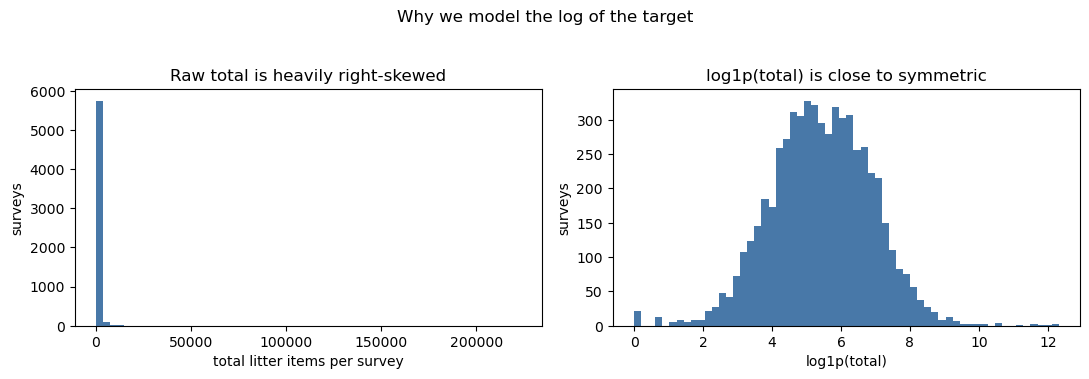

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].hist(df["total"].dropna(), bins=60, color="#4878A8")
axes[0].set_xlabel("total litter items per survey"); axes[0].set_ylabel("surveys")
axes[0].set_title("Raw total is heavily right-skewed")
axes[1].hist(df["log_total"].dropna(), bins=60, color="#4878A8")
axes[1].set_xlabel("log1p(total)"); axes[1].set_ylabel("surveys")
axes[1].set_title("log1p(total) is close to symmetric")
fig.suptitle("Why we model the log of the target", y=1.04)
fig.tight_layout(); plt.show()

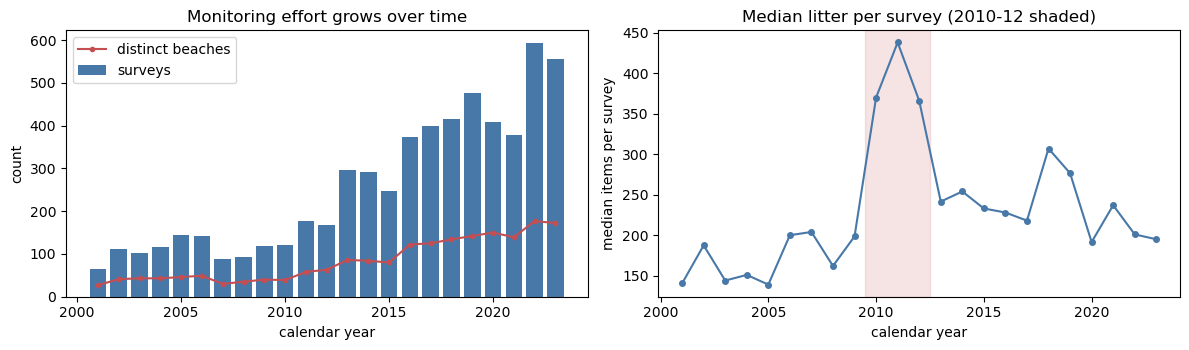

,surveys,beaches,median_total
date,,,
2001,64,27,140.5
2002,112,41,187.5
2003,103,43,144.0
2004,117,43,151.0
2005,145,46,139.0
2006,143,49,200.0
2007,89,30,204.0
2008,93,35,162.0
2009,118,40,198.5


In [15]:
year = df["date"].dt.year
by_year = df.groupby(year).agg(surveys=("total", "size"),
                               beaches=("Beach ID", "nunique"),
                               median_total=("total", "median"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(by_year.index, by_year["surveys"], color="#4878A8", label="surveys")
axes[0].plot(by_year.index, by_year["beaches"], color="#C44E52", marker="o",
             ms=3, label="distinct beaches")
axes[0].set_xlabel("calendar year"); axes[0].set_ylabel("count")
axes[0].set_title("Monitoring effort grows over time"); axes[0].legend()

axes[1].plot(by_year.index, by_year["median_total"], color="#4878A8", marker="o", ms=4)
axes[1].axvspan(2009.5, 2012.5, color="#C44E52", alpha=0.15)
axes[1].set_xlabel("calendar year"); axes[1].set_ylabel("median items per survey")
axes[1].set_title("Median litter per survey (2010-12 shaded)")
fig.tight_layout(); plt.show()

by_year.round(1)

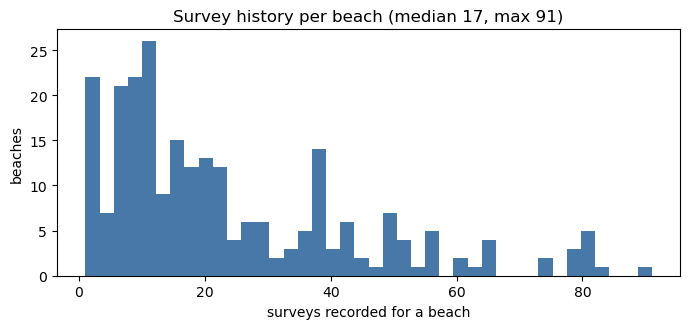

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(per_beach.values, bins=40, color="#4878A8")
ax.set_xlabel("surveys recorded for a beach"); ax.set_ylabel("beaches")
ax.set_title(f"Survey history per beach (median {int(per_beach.median())}, max {per_beach.max()})")
fig.tight_layout(); plt.show()

---
## 5. Two main takeaways from initial exploration:

### 5.1 There is a step change in 2010–2012, and part of it is a code change

Median litter per survey jumps from ~200 in 2007–09 to 370/438/366 in 2010/11/12, then
falls back to ~240. Three candidate explanations: new countries joining, different beaches
being surveyed, or a change in how litter was counted.

Restricting to the 35 beaches surveyed in all three windows
keeps the step almost unchanged.

In [17]:
yr = df["date"].dt.year
w1 = set(df.loc[yr.between(2007, 2009), "Beach ID"])
w2 = set(df.loc[yr.between(2010, 2012), "Beach ID"])
w3 = set(df.loc[yr.between(2013, 2015), "Beach ID"])
stable = w1 & w2 & w3
sub = df[df["Beach ID"].isin(stable)]

print(f"beaches surveyed in all three windows: {len(stable)}\n")
for lo, hi in [(2007, 2009), (2010, 2012), (2013, 2015)]:
    s = sub[yr.loc[sub.index].between(lo, hi)]
    print(f"  {lo}-{hi}:  n={len(s):4d}   median={s['total'].median():7.1f}   mean={s['total'].mean():8.1f}")

beaches surveyed in all three windows: 35

  2007-2009:  n= 253   median=  205.0   mean=   554.5
  2010-2012:  n= 306   median=  386.5   mean=   741.5
  2013-2015:  n= 349   median=  232.0   mean=   592.4


**Litter is plastic.** Every other material is flat or declining across the same
windows and the same beaches, which is not what a real environmental pulse would look like.

In [18]:
materials = {}
for c in counts:
    materials.setdefault(str(c).split(":")[0], []).append(c)

rows = {}
for name, cols in materials.items():
    rows[name] = {f"{lo}-{hi}": sub.loc[yr.loc[sub.index].between(lo, hi), cols].sum(axis=1).median()
                  for lo, hi in [(2007, 2009), (2010, 2012), (2013, 2015)]}
pd.DataFrame(rows).T.round(1)

,2007-2009,2010-2012,2013-2015
Plastic,133.0,307.0,181.0
Rubber,6.0,5.5,3.0
Cloth,2.0,2.0,1.0
Paper,3.0,5.0,2.0
Wood,6.0,5.0,2.0
Metal,7.0,6.0,3.0
Glass,3.0,3.0,1.0
Pottery,0.0,0.0,0.0
San,6.0,6.0,2.0
Med,0.0,0.0,0.0


**And four litter codes are exactly zero through 2009 and nonzero from 2010 onwards** —
the same signature as the 2015 sub-code change, which means OSPAR expanded the code list
in 2010 too. This was not in our original plan and nothing in the documentation told us;
the data did.

In [19]:
pre2010 = df[yr <= 2009]
new_in_2010 = []
for c in counts:
    if pre2010[c].fillna(0).sum() == 0 and df[c].fillna(0).sum() > 0:
        new_in_2010.append({"column": str(c),
                            "first year with a nonzero": int(yr[df[c].fillna(0) > 0].min()),
                            "lifetime total": int(df[c].sum())})
pd.DataFrame(new_in_2010)

,column,first year with a nonzero,lifetime total
0,Plastic: Bag_ends [112],2010,4300
1,Plastic: Fish_tags [114],2010,1725
2,Plastic: Rope [31],2010,45926
3,Wood: Fish_boxes [119],2010,115


The 2010 code expansion is demonstrable, but it is not large
enough to explain the whole step — `Plastic: Rope [31]` adds roughly 19 items per survey
against a mean jump of about 190. Most of the rest sits in `String [32]` and the plastic
fragment codes, which existed before 2010 but are counted several times more often after
it. That is consistent with a broader change in counting guidance, which we cannot prove
from the data alone.

### 5.2 The 21 zero-total surveys are mostly real

21 surveys across 10 beaches record a total of exactly zero. The question is whether they
are clean beaches or unreported surveys — it changes whether they belong in the panel.

In [20]:
zeros = df[df["total"] == 0]
summary = []
for bid in zeros["Beach ID"].unique():
    s = df[df["Beach ID"] == bid]
    summary.append({
        "Beach ID": bid,
        "Country": s["Country"].iloc[0],
        "surveys": len(s),
        "zero surveys": int((s["total"] == 0).sum()),
        "median of nonzero surveys": s.loc[s["total"] > 0, "total"].median(),
    })
pd.DataFrame(summary).sort_values("zero surveys", ascending=False)

,Beach ID,Country,surveys,zero surveys,median of nonzero surveys
8,UK046,United Kingdom,11,4,26.0
2,GRL003,Denmark (incl. the Faeroe Islands),6,3,1.0
3,GRL004,Denmark (incl. the Faeroe Islands),3,3,NaN
7,PT012,Portugal,39,3,56.5
1,ES009,Spain,4,2,20.0
4,GRL005,Denmark (incl. the Faeroe Islands),3,2,3.0
0,ES003,Spain,64,1,41.0
5,GRL006,Denmark (incl. the Faeroe Islands),1,1,NaN
6,IS002,Iceland,17,1,30.5
9,UK048,United Kingdom,25,1,90.5


Six of the ten are Greenland and Icelandic beaches whose *nonzero* surveys have medians of
1–3 items. A zero on a beach that otherwise yields one item is entirely credible, so these
are **real observations and we keep them**. `GRL004` and `GRL006` are zero across their
whole recorded history.

`UK046` is the one to watch: 4 zeros out of 11 surveys on a beach whose nonzero median is
26. That is worth a look at its remarks field before we trust it.

---
## 6. Baselines for our project comparison

Before any modeling, the benchmark has to be right. The proposal assumed "predict the
previous survey's value" as the baseline to beat. On this panel that is the **worse** of
the two obvious baselines.

In [21]:
# Evaluate on the modeling set the project question is scoped to: beaches with
# at least 8 surveys, so every row has real history behind it.
model_df = load_panel(min_surveys=8)
lagged = add_lags(model_df)
ok = lagged.dropna(subset=["prev_total_1", "beach_median_to_date"])

print(f"beaches with >= 8 surveys: {model_df['Beach ID'].nunique()}  "
      f"({len(model_df)} surveys, {len(ok)} usable transitions)\n")

for name, pred in [("previous survey's value", ok["prev_total_1"]),
                   ("beach's running median", ok["beach_median_to_date"]),
                   ("one global median", ok["total"].median())]:
    print(f"  {name:26s} MAE {(ok['total'] - pred).abs().mean():7.1f}")
print("\n  -> the running median is the baseline to beat, not the previous value")

beaches with >= 8 surveys: 197  (5668 surveys, 5471 usable transitions)

  previous survey's value    MAE   820.6
  beach's running median     MAE   602.0
  one global median          MAE   698.6

  -> the running median is the baseline to beat, not the previous value


Every feature in `add_lags` uses **only surveys that happened before the row's own
survey** — the running median is shifted by one so a survey never contributes to its own
baseline. This is the leakage rule the whole project depends on: the current survey's
litter breakdown *sums to the target*, so none of those columns can ever be a predictor.

In [22]:
# Most of the apparent predictability is between beaches, not within them.
pooled = ok[["prev_log_total_1", "log_total"]].corr().iloc[0, 1]
dm = ok.copy()
for col in ("prev_log_total_1", "log_total"):
    dm[col] = dm[col] - dm.groupby("Beach ID")[col].transform("mean")
within = dm[["prev_log_total_1", "log_total"]].corr().iloc[0, 1]

print(f"corr(prev, current) pooled across all surveys: {pooled:+.3f}")
print(f"corr(prev, current) within beach (demeaned):   {within:+.3f}")
print("\nThe gap is the point: a model can look strong simply by learning which beaches")
print("are dirty. The within-beach number is the honest measure of what we are adding.")

corr(prev, current) pooled across all surveys: +0.702
corr(prev, current) within beach (demeaned):   +0.277

The gap is the point: a model can look strong simply by learning which beaches
are dirty. The within-beach number is the honest measure of what we are adding.


The train/test split has to keep both code-change boundaries inside the training
period, so that neither validation nor test measures a change in counting rules.


In [23]:
yr_ok = ok["date"].dt.year
for name, mask in [("train  (<= 2018)", yr_ok <= 2018),
                   ("val    (2019-20)", yr_ok.between(2019, 2020)),
                   ("test   (2021-23)", yr_ok >= 2021)]:
    print(f"  {name}  n={int(mask.sum()):5d}   beaches={ok.loc[mask, 'Beach ID'].nunique():4d}")
print("\n  2010 and 2015 both fall inside the training period.")


  train  (<= 2018)  n= 3227   beaches= 155
  val    (2019-20)  n=  841   beaches= 142
  test   (2021-23)  n= 1403   beaches= 159

  2010 and 2015 both fall inside the training period.


---
## 7. Revised project question

> For OSPAR-monitored beaches with at least 8 recorded surveys, can the total litter count
> of a beach's next 100 m survey be predicted from information available before that survey
> — prior survey history, season, location and survey spacing — with a lower mean absolute
> error than the beach's own running median?

**What changed from the proposal, and why**

1. **Source.** The
   portal could not serve the full range, so 2015–2023 comes from ODIMS and 2001–2014 from
   three chunked portal exports. Same database, verified through the December 2014 overlap.
2. **Coverage is wider, not narrower.** 2001–2023 and 5,879 surveys, against the 2001–2020
   the portal advertises.
3. **Personal data.** The proposal said the data were non-personal. It carries surveyor
   names and emails, which we dropped and redacted.  
4. **Baseline.** The benchmark is the beach's running median, not the previous value of litter on a given beach.
5. **Scope.** 100 m protocol only; the 1 km protocol is a different method.